# 11 - The honest backtest: walk-forward evaluation, horizons and the interval score

> "The vendor's deck showed 4% error. In production it was 11%. What did their backtest do?" - Kestrel head of operations

The head of operations is not really asking about the vendor's model. Nothing about the
model changed between the slide and the server room; only the honesty of the measurement
did. That is the optimism gap notebook 01 caught on Hearthstone's training residuals,
now hiding one level up, inside the evaluation protocol. A backtest is a simulation of
deployment: at every forecast origin it must know exactly what the deployed model would
have known on that day, and nothing more. Anything the future would not have handed
over (a neighbouring hour, a centred average, a calibration error from next week) must be
invisible to it. The sharper statistical question: which evaluation protocol makes the
backtest's MAE, coverage and band width an honest preview of production, and how do we
test that the protocol is not peeking?

**What you will learn**

- The three standard ways a backtest lies, committed live on Kestrel's data, with the
  size of the flattery each one buys.
- How to implement a leakage-free rolling-origin backtest: refit per block, calibrate on
  earlier data, and purge the origins whose targets arrive after the block starts, so no
  target the model or the calibrator sees lies in the future.
- How to run the leakage test (shuffle the series in time; honest skill must vanish), what
  it can and cannot detect, and the code-level check that covers its blind spot.
- Why every horizon needs its own band, why 90% per hour is far from 90% per day (joint
  coverage), and how the interval score stops anyone from buying coverage with width.
- The benchmark table layout (family x horizon x method x MAE, coverage, width, interval
  score) that notebook 12 fills in.

**Where we are in the series.** Notebook 10 introduced Kestrel's two series, the four
simple rules and the percentile reference band, and showed on a single holdout that a
time series' misses arrive in bursts. This notebook builds the evaluation protocol that
every later Part II notebook reuses. Notebook 12 then upgrades the band from absolute
residuals to CQR, adds a pre-trained stand-in, and fills in the benchmark table we
template in section 8. From Part I we lean on notebook 02 (split conformal and the
corrected quantile), notebook 03 (the leaderboard argument and exchangeability) and field
guide §2 (never calibrate on anything the model has seen); from notebook 09, on the idea
that a permutation is a test.

## 1. Three ways a backtest lies

Every flattering backtest we have seen in practice commits at least one of three sins.
None of them raises an error; each one quietly moves the evaluation closer to the past it
was trained on, so the numbers improve while their meaning evaporates.

| Lie | What it looks like in code | How it inflates the number | The guard |
|---|---|---|---|
| 1. A random split of time-ordered rows | `train_test_split(tab, shuffle=True)`, `KFold(shuffle=True)` on hourly rows | every test hour has its neighbours (same day, same weather, same tenant) in the training set, so the model interpolates instead of forecasting; calibration rows are exchangeable with test rows by construction, so coverage looks perfect | walk-forward blocks in time order (section 3, field guide §15) |
| 2. Features that peek | `y.rolling(24, center=True).mean()`; a scaler fitted on the whole series; observed weather in place of the forecast issued at the origin; `early_stopping="auto"` with a random holdout | part of the answer is inside the inputs; MAE drops, sometimes collapses, and the conformal band shrinks with it | build every feature from values known at the origin, then run both leakage checks: the shuffle test and the future-scramble check, which alone catches a whole-series scaler (section 4, field guide §16) |
| 3. Calibrating or tuning on the test period | `q_hat` computed from the test block's own residuals; features, hyperparameters or "the best model" picked by test-period score; no purge, so calibration targets lie after the origin | coverage lands on target by construction and the block-to-block spread disappears; whatever got luckiest on the test period wins | calibrate on earlier data, purge `h` rows, freeze every choice before the test period starts (sections 3 and 8) |

One trap in that table hides inside a library default, and it is the reason the shared
`quantile_gbm` sets `early_stopping=False`. scikit-learn's `HistGradientBoostingRegressor`
defaults to `early_stopping="auto"`, which switches early stopping on whenever the
training set has more than 10,000 rows - every building training set in this notebook
does - and then decides when to stop adding trees by scoring a *random* 10% of the
training rows (`validation_fraction=0.1`). On time-ordered data that is lie number one,
committed inside `fit`: the validation hours sit between training hours from the same
days, so the stopping rule rewards a model that interpolates its neighbours, and nobody
reading the pipeline sees a split at all. The honest alternatives are a fixed number of
trees chosen once (what `quantile_gbm` does with `max_iter=60`) or a validation block
carved from the *end* of the training window, purged like everything else.

The tools for the rest of the notebook are copied verbatim from the shared Part II code,
docstrings included - read them, because later notebooks test their claims: the two
simulators from notebook 10, `make_direct_table` with the `BASELINES` and
`MODEL_FEATURES` lists, `quantile_gbm`, `walk_forward_blocks`, `interval_score`,
`band_report` and `corrected_quantile`. The point forecast throughout is the median
quantile GBM; the band is notebook 02's recipe - prediction plus or minus the corrected
quantile of absolute calibration errors. Notebook 12 swaps that band for CQR; the
protocol built here does not change. One declared assumption: the building model reads
the temperature at the target hour (`exog_at_target`) as if it were a weather forecast
issued at the origin. In the simulation it is the actual temperature, a perfect forecast.
In the real project, use archived forecasts; the measured temperature is lie number two
in disguise.

In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap

import sklearn                                # loads the OpenMP runtime the limit below acts on
from threadpoolctl import threadpool_limits   # installed with scikit-learn

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
RANDOM_SEED = 20260707
ALPHA = 0.10   # the project's 90% band

# Series palette: blue = data, green = covered/healthy, amber = calibration/warning,
# red = missed/fault/naive, gray = reference, purple = alternative method.
BLUE, GREEN, AMBER, RED, GRAY, PURPLE = (
    "#2563EB", "#059669", "#F59E0B", "#DC2626", "#6B7280", "#7C3AED",
)

# This notebook fits about 130 small models. HistGradientBoosting spreads each fit over
# every CPU core; on tables this small the coordination costs more than it saves, and on a
# busy laptop it can make every fit several times slower. One thread is plenty here, and
# it does not change a single prediction. (Keep the returned object: it holds the limit.)
THREAD_LIMIT = threadpool_limits(1, user_api="openmp")

In [2]:
# Copied verbatim from the shared Part II code; notebook 10 introduced both series.
def simulate_building_load(n_days, seed, start="2016-01-01", base_kwh=120.0,
                           occupied_kwh=180.0, hvac_kwh_per_deg=6.0, noise_frac=0.06,
                           shift_day=None, shift_frac=0.0):
    """Simulate an hourly electricity meter for one Kestrel office building.

    What the simulator bakes in (and what later notebooks test against):
    - A daily occupancy profile: busy 08:00-18:00 on weekdays, quiet nights and weekends.
      That is why 'same hour yesterday' and 'same hour last week' are strong baselines.
    - Heating and cooling: load rises when the outdoor temperature leaves a comfort zone,
      and the temperature follows the seasons, so summer and winter behave differently.
    - Noise that is autocorrelated (a busy morning tends to stay busy) and larger when the
      building is occupied. Residuals are neither independent nor equal-sized.
    - Optional regime change: from day `shift_day` on, the load level is multiplied by
      (1 + shift_frac) - a new tenant, a retrofit. Notebook 15 uses it to break calibration.

    Returns a DataFrame indexed by hourly timestamp with columns `load_kwh` and `temp_c`.
    """
    rng = np.random.default_rng(seed)
    idx = pd.date_range(start, periods=24 * n_days, freq="h")
    n = len(idx)
    hour = idx.hour.to_numpy()
    dow = idx.dayofweek.to_numpy()
    doy = idx.dayofyear.to_numpy()

    # Weather: seasons + a daily cycle + persistent anomalies (a cold week stays cold).
    anomaly = np.zeros(n)
    shocks = rng.normal(0.0, 0.6, size=n)
    for i in range(1, n):
        anomaly[i] = 0.97 * anomaly[i - 1] + shocks[i]
    temp = 12.0 - 10.0 * np.cos(2 * np.pi * (doy - 15) / 365.25) \
        + 4.0 * np.sin(2 * np.pi * (hour - 9) / 24) + anomaly

    # Occupancy: weekdays 08-18, with half-occupied shoulder hours at 07 and 18.
    occupied = ((dow < 5) & (hour >= 8) & (hour < 18)).astype(float)
    shoulder = ((dow < 5) & ((hour == 7) | (hour == 18))).astype(float) * 0.5
    occ = occupied + shoulder

    hvac = hvac_kwh_per_deg * (1.3 * np.maximum(temp - 22.0, 0.0)
                               + np.maximum(16.0 - temp, 0.0)) * (0.4 + 0.6 * occ)
    mean_load = base_kwh + occupied_kwh * occ + hvac

    # Autocorrelated, occupancy-dependent multiplicative noise.
    ar = np.zeros(n)
    z = rng.normal(0.0, 1.0, size=n)
    for i in range(1, n):
        ar[i] = 0.8 * ar[i - 1] + math.sqrt(1 - 0.8 ** 2) * z[i]
    load = mean_load * (1.0 + noise_frac * (1.0 + occ) * ar)

    if shift_day is not None:
        load = np.where(np.arange(n) >= 24 * shift_day, load * (1.0 + shift_frac), load)
    return pd.DataFrame({"load_kwh": np.maximum(load, 0.0), "temp_c": temp}, index=idx)


def simulate_vm_cpu(n_days, seed, start="2019-01-01", base_pct=22.0, daily_amp=8.0,
                    bursts_per_day=5.0, n_redeploys=2):
    """Simulate 5-minute average CPU utilisation (%) for one Kestrel virtual machine.

    What the simulator bakes in (and what later notebooks test against):
    - A weak daily rhythm (busier in business hours) on top of a level that jumps when the
      service is redeployed. The jumps are sudden and unannounced.
    - Bursts: spikes arriving at random times (batch jobs, traffic surges) that decay over
      a few readings. They make the series bursty - the reason simple baselines are so hard
      to beat on cloud data.
    - Readings are clipped to [0, 100]. During heavy bursts the VM saturates and reports
      exactly 100.0 several readings in a row - a legitimate flat line that a naive
      stuck-sensor rule will mistake for a frozen gateway (notebook 13).

    Returns a DataFrame indexed by 5-minute timestamp with column `cpu_pct`.
    """
    rng = np.random.default_rng(seed)
    steps_per_day = 288
    n = steps_per_day * n_days
    idx = pd.date_range(start, periods=n, freq="5min")
    hour = idx.hour.to_numpy() + idx.minute.to_numpy() / 60.0

    # Level that jumps at redeployments.
    level = np.full(n, base_pct)
    for when in np.sort(rng.integers(steps_per_day * 2, n, size=n_redeploys)):
        level[when:] = level[when:] * rng.lognormal(0.0, 0.35)

    daily = daily_amp * np.clip(np.sin(np.pi * (hour - 7) / 12), 0.0, None)

    # Bursts: random arrivals, random heights, exponential decay over a few readings.
    burst = np.zeros(n)
    n_bursts = rng.poisson(bursts_per_day * n_days)
    for start_step, height, decay in zip(rng.integers(0, n, size=n_bursts),
                                         rng.exponential(35.0, size=n_bursts),
                                         rng.uniform(2.0, 10.0, size=n_bursts)):
        span = np.arange(start_step, min(start_step + int(6 * decay), n))
        burst[span] += height * np.exp(-(span - start_step) / decay)

    ar = np.zeros(n)
    z = rng.normal(0.0, 1.0, size=n)
    for i in range(1, n):
        ar[i] = 0.6 * ar[i - 1] + z[i]
    cpu = level + daily + burst + 2.5 * ar
    return pd.DataFrame({"cpu_pct": np.clip(cpu, 0.0, 100.0)}, index=idx)

In [3]:
# Copied verbatim from the shared Part II code: the leakage-safe table, the column lists,
# the model, the walk-forward blocks and the metrics.
def make_direct_table(y, h, period, exog=None):
    """Turn a series into a supervised table for forecasting h steps ahead.

    One row per forecast origin t. Every feature uses only values known at time t
    (y[t], y[t-1], ...); the target is y[t + h]. `period` is the number of steps per day
    (24 for hourly meters, 288 for 5-minute CPU). Requires h <= period, so that 'same time
    yesterday' (relative to the target) is already observed at the origin.

    The four simple baselines and the past-percentile reference band are columns of this
    table, computed with exactly the same no-peeking rule as the model features.
    """
    assert h <= period, "h must not exceed one day, or 'same time yesterday' is in the future"
    v = y.to_numpy(dtype=float)
    n = len(v)
    target_pos = np.arange(n) + h

    def at(offset):
        """Value at position (t + offset) for every origin t; NaN when out of range."""
        pos = np.arange(n) + offset
        out = np.full(n, np.nan)
        ok = (pos >= 0) & (pos < n)
        out[ok] = v[pos[ok]]
        return out

    same_time_past_days = np.column_stack([at(h - k * period) for k in range(1, 15)])
    table = pd.DataFrame({
        "last_value": v,
        "mean_last_day": pd.Series(v).rolling(period).mean().to_numpy(),
        "same_time_yesterday": same_time_past_days[:, 0],
        "same_time_last_week": same_time_past_days[:, 6],
        "median_14d_same_time": np.median(same_time_past_days, axis=1),
        "p05_14d_same_time": np.percentile(same_time_past_days, 5, axis=1),
        "p95_14d_same_time": np.percentile(same_time_past_days, 95, axis=1),
    }, index=y.index)
    target_time = y.index + h * (y.index[1] - y.index[0])
    table["target_hour"] = target_time.hour + target_time.minute / 60.0
    table["target_dow"] = target_time.dayofweek
    if exog is not None:
        # Treated as a forecast known in advance (e.g. tomorrow's weather forecast).
        e = exog.to_numpy(dtype=float)
        exog_at_target = np.full(n, np.nan)
        ok = target_pos < n
        exog_at_target[ok] = e[target_pos[ok]]
        table["exog_at_target"] = exog_at_target
    table["target"] = at(h)
    table["target_time"] = target_time
    return table.dropna().copy()


BASELINES = ["last_value", "same_time_yesterday", "same_time_last_week", "median_14d_same_time"]
MODEL_FEATURES = ["last_value", "mean_last_day", "same_time_yesterday", "same_time_last_week",
                  "median_14d_same_time", "target_hour", "target_dow"]


def quantile_gbm(q, seed=20260707):
    """Gradient-boosted quantile model used by every Part II notebook.

    Small and fast on purpose (each fit takes well under a second). early_stopping=False
    matters: scikit-learn's automatic early stopping holds out a RANDOM 10% of rows, which
    on time-ordered data quietly lets the model peek at its own future.
    """
    from sklearn.ensemble import HistGradientBoostingRegressor
    return HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=60,
                                         learning_rate=0.15, max_leaf_nodes=15,
                                         early_stopping=False, random_state=seed)


def walk_forward_blocks(n_rows, first_test_row, block_len, cal_len, h):
    """Yield (train_rows, cal_rows, test_rows) position arrays for rolling-origin evaluation.

    Rows are forecast origins in time order. For each block starting at row s:
    - test rows are [s, s + block_len): forecasts issued during the block;
    - calibration rows are the cal_len origins whose targets are all observed by time s,
      i.e. rows [s - h - cal_len + 1, s - h];
    - training rows end h rows before calibration starts, so no training target overlaps
      the calibration period (a purge of h rows).
    The model is re-fitted before every block on the training rows only.
    """
    s = first_test_row
    while s < n_rows:
        cal_end = s - h + 1
        cal_start = cal_end - cal_len
        train_end = cal_start - h
        assert train_end > 0, "not enough history before the first block"
        yield (np.arange(0, train_end), np.arange(cal_start, cal_end),
               np.arange(s, min(s + block_len, n_rows)))
        s += block_len


def interval_score(y, lo, hi, alpha):
    """Gneiting-Raftery interval score of a central (1 - alpha) band; lower is better.

    Width, plus a penalty of 2/alpha per unit of distance for every observation that lands
    outside the band. A band that is too narrow pays in misses; a band that is too wide
    pays in width. Averaged over observations.
    """
    y, lo, hi = np.asarray(y), np.asarray(lo), np.asarray(hi)
    return float(np.mean((hi - lo)
                         + (2.0 / alpha) * np.maximum(lo - y, 0.0)
                         + (2.0 / alpha) * np.maximum(y - hi, 0.0)))


def band_report(y, point, lo, hi, alpha):
    """MAE of the point forecast, plus coverage, mean width and interval score of the band."""
    y, point, lo, hi = map(np.asarray, (y, point, lo, hi))
    return {
        "MAE": float(np.mean(np.abs(y - point))),
        "coverage": float(np.mean((y >= lo) & (y <= hi))),
        "width": float(np.mean(hi - lo)),
        "interval_score": interval_score(y, lo, hi, alpha),
    }


def corrected_quantile(scores, alpha):
    """The corrected quantile from notebook 02: the k-th smallest score, k = ceil((n+1)(1-alpha))."""
    n = len(scores)
    k = math.ceil((n + 1) * (1 - alpha))
    assert k <= n, "calibration window too short for this alpha (field guide S1)"
    return float(np.sort(scores)[k - 1])

In [4]:
b = simulate_building_load(730, seed=RANDOM_SEED)   # hourly kWh, 2016-2017 (like BDG2)
v = simulate_vm_cpu(30, seed=RANDOM_SEED)           # 5-minute CPU %, 30 days (like Azure)

# The building model also reads the temperature at the target hour, treated as a weather
# forecast issued at the origin (section 1). The VM model has no outside information.
BUILDING_FEATURES = MODEL_FEATURES + ["exog_at_target"]

# Part II protocol constants: test on the last 24 weeks (building) or 8 days (VM); refit
# every 4 weeks or 2 days; calibrate on the latest 4 weeks or 1 day of scorable origins.
SETTINGS = {
    "building": dict(series=b["load_kwh"], exog=b["temp_c"], period=24, horizons=(1, 24),
                     features=BUILDING_FEATURES, test_len=24 * 7 * 24,
                     block_len=24 * 28, cal_len=24 * 28),
    "vm": dict(series=v["cpu_pct"], exog=None, period=288, horizons=(1, 12, 48),
               features=MODEL_FEATURES, test_len=288 * 8,
               block_len=288 * 2, cal_len=288),
}
tables = {(fam, h): make_direct_table(cfg["series"], h, cfg["period"], exog=cfg["exog"])
          for fam, cfg in SETTINGS.items() for h in cfg["horizons"]}

for (fam, h), tab in tables.items():
    cfg = SETTINGS[fam]
    blocks = list(walk_forward_blocks(len(tab), len(tab) - cfg["test_len"],
                                      cfg["block_len"], cfg["cal_len"], h))
    print(f"{fam:>8} h={h:<3} readings {len(cfg['series']):>6,}   table rows {len(tab):>6,}   "
          f"test rows {cfg['test_len']:>5,} in {len(blocks)} blocks   "
          f"first training window {len(blocks[0][0]):>6,} rows   "
          f"first usable origin {tab.index[0]:%Y-%m-%d %H:%M}")

building h=1   readings 17,520   table rows 17,184   test rows 4,032 in 6 blocks   first training window 12,479 rows   first usable origin 2016-01-14 23:00
building h=24  readings 17,520   table rows 17,184   test rows 4,032 in 6 blocks   first training window 12,433 rows   first usable origin 2016-01-14 00:00
      vm h=1   readings  8,640   table rows  4,608   test rows 2,304 in 4 blocks   first training window  2,015 rows   first usable origin 2019-01-14 23:55
      vm h=12  readings  8,640   table rows  4,608   test rows 2,304 in 4 blocks   first training window  1,993 rows   first usable origin 2019-01-14 23:00
      vm h=48  readings  8,640   table rows  4,608   test rows 2,304 in 4 blocks   first training window  1,921 rows   first usable origin 2019-01-14 20:00


The printout is the protocol's budget. Every building table has 17,184 rows from 17,520
hourly readings: 336 origins are lost, almost all of them at the start, where the 14-day
same-time features do not yet have two weeks of history (the last `h` origins go too:
their targets lie beyond the data). The VM pays the same toll at its own resolution -
4,032 of its 8,640 origins, essentially its first 14 days out of 30 - which leaves 4,608
rows, half of them in the test period. That is real and worth one sentence in any report:
a newly deployed VM gets no model at all for two weeks, and a cold-start plan (notebook 15) has to say what
runs instead. The test periods are the Part II constants: 4,032 building origins in six
four-week blocks, 2,304 VM origins in four two-day blocks. And note the first training
windows: 12,479 and 12,433 rows for the building, above the 10,000-row line where
`early_stopping="auto"` would have silently switched itself on. What the printout cannot
tell you is whether any of these rows will be used honestly; that is the rest of the
notebook.

## 2. Lie number one, committed

The most common backtest in the wild is the one every tutorial teaches for tabular data:
shuffle the rows, cut 80/20. We commit it on the building's day-ahead table (h = 24),
with a quarter of the 80% held out as the calibration set (a 60/20/20 split), then run the
identical pipeline on an unshuffled, chronological 60/20/20 split - train on the oldest
60% of origins, calibrate on the next 20%, test on the latest 20%. Same table, same
model, same conformal recipe; the only difference is whether `rng.permutation` touched
the row order. (No purge yet; section 3 adds it.)

One fairness detail. A random test set is spread over both years, a chronological one sits
in the last months of 2017, so part of any gap could be the seasons rather than the leak.
We therefore also score the random-split model only on its test rows that fall in the
chronological test window: same weeks of the calendar, the only difference left is what
the model was allowed to train on. And because a leak is worth more when neighbours are
more alike than strangers, we repeat the comparison on the VM at h = 12 (one hour ahead),
whose bursts make neighbouring readings far more alike than distant ones.

In [5]:
# Lie number one, committed. Same table, same model, same conformal recipe; the ONLY
# difference is whether the rows are shuffled before the 60/20/20 cut.
rows = []
for fam, h in (("building", 24), ("vm", 12)):
    tab = tables[(fam, h)]
    X, y = tab[SETTINGS[fam]["features"]].to_numpy(), tab["target"].to_numpy()
    n = len(tab)
    n_train, n_cal = int(0.6 * n), int(0.2 * n)
    final_window = np.arange(n) >= n_train + n_cal          # the latest 20% of the calendar
    for split, order in (("random", np.random.default_rng(RANDOM_SEED).permutation(n)),
                         ("chronological", np.arange(n))):
        train, cal, test = order[:n_train], order[n_train:n_train + n_cal], order[n_train + n_cal:]
        model = quantile_gbm(0.5).fit(X[train], y[train])
        q_hat = corrected_quantile(np.abs(y[cal] - model.predict(X[cal])), ALPHA)
        point = model.predict(X[test])
        # The random-split model is also scored on its test rows inside the chronological
        # test window, so that both splits are judged on the same weeks of the calendar.
        views = {split: np.ones(len(test), dtype=bool)}
        if split == "random":
            views["random, scored on the latest 20% only"] = final_window[test]
        for label, keep in views.items():
            rows.append({"family": fam, "h": h, "split": label, "test rows": int(keep.sum()),
                         **band_report(y[test][keep], point[keep], point[keep] - q_hat,
                                       point[keep] + q_hat, ALPHA)})

lie_one = pd.DataFrame(rows).set_index(["family", "h", "split"])
lie_one.round(3)

test rows     MAE  coverage   width  interval_score
family   h  split                                                                                     
building 24 random                                      3438  14.217     0.899  77.460         117.968
            random, scored on the latest 20% only        648  14.577     0.894  77.460         120.309
            chronological                               3438  15.675     0.881  78.098         131.566
vm       12 random                                       923   4.621     0.902  17.399          43.671
            random, scored on the latest 20% only        163   5.506     0.865  17.399          56.405
            chronological                                923   6.875     0.833  20.206          64.009

The shuffled split wins on every column, which is exactly what makes it dangerous. On the
building's day-ahead table the random split reports MAE 14.217 kWh, coverage 0.899 and
interval score 117.97; the chronological split, scored on the latest 3,438 origins,
reports MAE 15.675, coverage 0.881 and interval score 131.57. Restricting the random
split to its 648 test rows inside the same calendar window barely moves it (MAE 14.577,
coverage 0.894), so the gap is not the seasons: it is the neighbours. A model that has
trained on other hours of the very days it is tested on has seen those days' weather
anomalies and noise; a deployed model never has. The flattery is modest on the building -
about 9% of MAE - probably because our simulator's physics never change and the lag
features already carry most of what a neighbouring hour could add.

The VM is the cautionary row. At one hour ahead the random split claims MAE 4.621 and
coverage 0.902; the chronological split delivers MAE 6.875 and coverage 0.833 - the random
split understates the error by a third and promises one miss in ten where deployment gets
one in six. Part of that gap is the calendar: scored only on its 163 test rows inside the
chronological window, the random split's MAE rises to 5.506 and its coverage falls to
0.865, so the last days of the VM's month are simply harder. On those same days it is
still 20% more accurate than the chronological split (163 rows is a small sample; read
that 20% as an order of magnitude), and two different things hide in that gap. One is the
leak: the random split trained on readings from the very bursts it is tested on. The other
is staleness, which is not a leak at all: the chronological model was fitted a whole
calibration window - about three days - before its test window began, and a deployed
model would have been refitted in between. Section 3's walk-forward refits every two days
and lets us split the gap.

Read the coverage column twice. The random split's 0.899 and 0.902 are not evidence of a
good band; they are the leaderboard argument of notebook 03 working exactly as designed,
on a calibration set that is exchangeable with the test set *because we shuffled it to
be*. The guarantee was real; the deployment it described does not exist (field guide §6, §15). What this table does not show yet is the
spread: a single chronological cut is one draw, and section 3 replaces it with six.

## 3. Walk-forward blocks

The honest protocol has a name: **walk-forward (rolling-origin) evaluation**. Cut the test
period into blocks in time order. Before each block, pretend it is the morning the block
starts: refit the model on everything that was known by then, calibrate the band on the
most recent errors that could have been scored by then, issue every forecast of the block
without touching the model or the band again, and only then roll the origin forward one
block. Each block is a dress rehearsal of one deployment cycle - refit and recalibrate
every four weeks for the building, every two days for the VM - and the backtest's numbers
are the average over rehearsals.

The subtle part is the **purge**. A row of our table is a forecast origin t, but its target
lives at t + h, so "rows before the block" is not the same as "information before the
block". The rule in words: every target the model or the calibrator sees must already have
happened when the block starts. For the calibration window that is the gap validity
requires: a calibration score is a forecast error, you cannot score a forecast whose
outcome has not arrived, and the origins just before the block have targets inside the
block - using them would calibrate on test-period outcomes, lie number three. The gap
between training and calibration is different: an **embargo**, conservative rather than
necessary. Training and calibration targets could never coincide even without it (a
training row and a calibration row are different origins, so their targets are different
hours), but without it the last training outcomes would sit right next to the first
calibration outcomes, and neighbouring hours are autocorrelated. The embargo costs `h`
training rows and buys calibration errors that are out-of-sample in the strictest sense:
the model has seen no outcome later than the first calibration origin. Concretely, for a
block whose first test origin is row `s`, `walk_forward_blocks` uses:

- calibration rows `[s - h - cal_len + 1, s - h]`: the latest `cal_len` origins whose
  targets (at most row `s`) are observed when the block starts;
- training rows `[0, s - 2h - cal_len + 1)`: their last target lands one step before the
  first calibration origin.

So there are two gaps: the embargo of `h` origins between training and calibration, and
the purge of `h - 1` origins between calibration and the block, whose targets are still in
the future at the block start. At h = 1 both cost nothing; at the day-ahead horizon each is
a day; at the VM's four-hour horizon, 48 readings before calibration and 47 before the
block. Cheap insurance, and the figure below draws both.

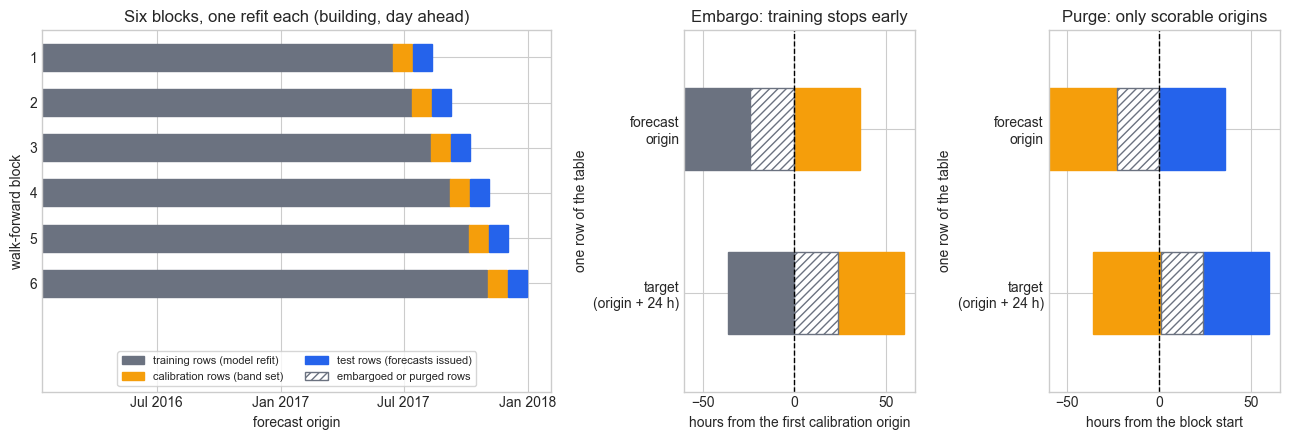

block 1: last training origin 2017-06-15 00:00 -> its target 2017-06-16 00:00
         first calibration origin 2017-06-16 01:00, last 2017-07-14 00:00 -> its target 2017-07-15 00:00
         first test origin (block start) 2017-07-15 00:00; embargoed origins: 24; purged origins: 23


In [6]:
# One picture of the protocol: the building's day-ahead (h = 24) blocks.
h, tab, cfg = 24, tables[("building", 24)], SETTINGS["building"]
blocks = list(walk_forward_blocks(len(tab), len(tab) - cfg["test_len"],
                                  cfg["block_len"], cfg["cal_len"], h))
origin_time = tab.index            # table row r is the forecast issued at origin_time[r]
STYLE = {"training": dict(facecolor=GRAY, edgecolor=GRAY),
         "calibration": dict(facecolor=AMBER, edgecolor=AMBER),
         "test": dict(facecolor=BLUE, edgecolor=BLUE),
         "purged": dict(facecolor="white", edgecolor=GRAY, hatch="////")}

def draw_boundary(ax, block, ref_row, title, xlabel):
    """Origins (upper track) and their targets (lower track) around one boundary, in hours."""
    train, cal, test = block
    rows = np.arange(ref_row - 60, ref_row + 36)
    hours = ((origin_time[rows] - origin_time[ref_row]) / pd.Timedelta(hours=1)).to_numpy()
    role = np.select([np.isin(rows, train), np.isin(rows, cal), np.isin(rows, test)],
                     ["training", "calibration", "test"], default="purged")
    for name, style in STYLE.items():
        x = hours[role == name]
        if len(x):   # each role is one contiguous run inside the zoom window
            for track, shift in ((1, 0), (0, h)):
                ax.barh(track, x.max() - x.min() + 1, left=x.min() + shift, height=0.5, **style)
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set_yticks([0, 1], [f"target\n(origin + {h} h)", "forecast\norigin"])
    ax.set_ylim(-0.6, 1.6)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("one row of the table")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2.2, 1, 1]})
ax = axes[0]
for k, block in enumerate(blocks, start=1):
    for rows, name in zip(block, ("training", "calibration", "test")):
        start, end = mdates.date2num(origin_time[rows[0]]), mdates.date2num(origin_time[rows[-1]])
        ax.barh(k, end - start, left=start, height=0.6, **STYLE[name])
ax.set_ylim(8.4, 0.4)              # block 1 on top; room for the legend underneath
ax.set_yticks(range(1, len(blocks) + 1))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("Six blocks, one refit each (building, day ahead)")
ax.set_xlabel("forecast origin")
ax.set_ylabel("walk-forward block")
handles = [plt.Rectangle((0, 0), 1, 1, **STYLE[name]) for name in STYLE]
ax.legend(handles, ["training rows (model refit)", "calibration rows (band set)",
                    "test rows (forecasts issued)", "embargoed or purged rows"],
          loc="lower center", ncol=2, fontsize=8, frameon=True)

draw_boundary(axes[1], blocks[0], blocks[0][1][0], "Embargo: training stops early",
              "hours from the first calibration origin")
draw_boundary(axes[2], blocks[0], blocks[0][2][0], "Purge: only scorable origins",
              "hours from the block start")
plt.tight_layout()
plt.show()

train, cal, test = blocks[0]
print(f"block 1: last training origin {origin_time[train[-1]]:%Y-%m-%d %H:%M} "
      f"-> its target {origin_time[train[-1]] + pd.Timedelta(hours=h):%Y-%m-%d %H:%M}")
print(f"         first calibration origin {origin_time[cal[0]]:%Y-%m-%d %H:%M}, "
      f"last {origin_time[cal[-1]]:%Y-%m-%d %H:%M} -> its target "
      f"{origin_time[cal[-1]] + pd.Timedelta(hours=h):%Y-%m-%d %H:%M}")
print(f"         first test origin (block start) {origin_time[test[0]]:%Y-%m-%d %H:%M}; "
      f"embargoed origins: {cal[0] - train[-1] - 1}; purged origins: {test[0] - cal[-1] - 1}")

The left panel is the whole protocol at a glance: six rows, each a full deployment cycle.
The gray training window grows by four weeks per block (the model is refitted from scratch
on all history), the amber calibration window is always the four weeks just before the
block, and the blue test blocks tile the last 24 weeks of 2017 without overlapping. At
this scale the gaps are invisible - a day out of two years - which is precisely why they
are so easy to forget.

The two zooms show them; each hour is drawn as a one-hour-wide slot. In the middle panel
the gray training targets (lower track) end in the slot just before hour 0, the first
calibration origin; the 24 hatched origins before it are embargoed, because their targets
would have fallen in the hours just before the first calibration target, next-door
neighbours of the outcomes the band is calibrated on. In the right panel the amber calibration
targets reach the hour-0 slot - the block start, the latest outcome anyone can have seen
that morning - and no further; the 23 hatched origins between calibration and block are
purged because their targets were still in the future. The printout says the same in
timestamps: the last training origin, 2017-06-15 00:00,
forecasts 2017-06-16 00:00, one hour before the first calibration origin at 2017-06-16
01:00; the last calibration origin, 2017-07-14 00:00, forecasts 2017-07-15 00:00, the
very first test origin of the block. What the figure does not show is any number: the
protocol is only as honest as the features inside it, which is section 4's job.

In [7]:
def walk_forward_abs_band(tab, features, h, test_len, block_len, cal_len, alpha=ALPHA):
    """Rolling-origin backtest: median GBM plus notebook 02's absolute-residual band.

    Before every block the model is re-fitted on the training rows only; the calibration
    rows (origins whose targets are all observed when the block starts) are scored by
    |y - prediction|; the corrected quantile of those scores is the half-width of every
    band issued during the block. Nothing from the block itself is touched.
    Returns one row per test origin, and the calibration scores of every block.
    """
    X, y = tab[features].to_numpy(), tab["target"].to_numpy()
    target_time = tab["target_time"].to_numpy()
    pieces, cal_scores = [], {}
    blocks = walk_forward_blocks(len(tab), len(tab) - test_len, block_len, cal_len, h)
    for k, (train, cal, test) in enumerate(blocks, start=1):
        model = quantile_gbm(0.5).fit(X[train], y[train])
        scores = np.abs(y[cal] - model.predict(X[cal]))
        q_hat = corrected_quantile(scores, alpha)
        point = model.predict(X[test])
        pieces.append(pd.DataFrame({
            "block": k, "target_time": target_time[test], "y": y[test], "point": point,
            "lo": point - q_hat, "hi": point + q_hat, "q_hat": q_hat,
            "train_rows": len(train),
            # The two constant forecasts the leakage test compares against (section 4).
            "train_median": np.median(y[train]), "train_mean": y[train].mean(),
        }))
        cal_scores[k] = scores
    return pd.concat(pieces, ignore_index=True), cal_scores


runs = {}
for (fam, h), tab in tables.items():
    cfg = SETTINGS[fam]
    runs[(fam, h)] = walk_forward_abs_band(tab, cfg["features"], h, cfg["test_len"],
                                           cfg["block_len"], cfg["cal_len"])

rows = []
for (fam, h), (res, _) in runs.items():
    for k, blk in res.groupby("block"):
        errors = np.abs(blk["y"] - blk["point"]).to_numpy()
        q_own = corrected_quantile(errors, ALPHA)   # lie number three: calibrate on the block itself
        rows.append({"family": fam, "h": h, "block": k,
                     "first target": f"{blk['target_time'].min():%Y-%m-%d}",
                     "MAE": errors.mean(),
                     "coverage": np.mean((blk["y"] >= blk["lo"]) & (blk["y"] <= blk["hi"])),
                     "width": (blk["hi"] - blk["lo"]).mean(),
                     "coverage if calibrated on the block itself": np.mean(errors <= q_own)})
per_block = pd.DataFrame(rows).set_index(["family", "h", "block"])

for (fam, h), (res, _) in runs.items():
    rep = band_report(res["y"], res["point"], res["lo"], res["hi"], ALPHA)
    cov = per_block.loc[(fam, h), "coverage"]
    print(f"{fam:>8} h={h:<3} MAE {rep['MAE']:6.2f}   coverage {rep['coverage']:.3f} "
          f"(blocks {cov.min():.3f} to {cov.max():.3f})   width {rep['width']:6.1f}   "
          f"interval score {rep['interval_score']:6.1f}")

# Section 2's chronological test windows, re-scored with these walk-forward forecasts
# (both are the latest rows of the same table): how much of section 2's gap was staleness?
for fam, h in (("building", 24), ("vm", 12)):
    n_window = int(lie_one.loc[(fam, h, "chronological"), "test rows"])
    window = runs[(fam, h)][0].iloc[-n_window:]
    print(f"{fam:>8} h={h:<3} section 2's latest {n_window:,} origins: walk-forward MAE "
          f"{np.mean(np.abs(window['y'] - window['point'])):.3f}   (chronological split "
          f"{lie_one.loc[(fam, h, 'chronological'), 'MAE']:.3f}, random split on the same "
          f"weeks {lie_one.loc[(fam, h, 'random, scored on the latest 20% only'), 'MAE']:.3f})")
per_block.round(3)

building h=1   MAE   9.85   coverage 0.897 (blocks 0.874 to 0.920)   width   51.9   interval score   81.2
building h=24  MAE  15.78   coverage 0.894 (blocks 0.857 to 0.935)   width   84.2   interval score  133.8
      vm h=1   MAE   2.67   coverage 0.899 (blocks 0.892 to 0.903)   width    9.4   interval score   19.8
      vm h=12  MAE   5.73   coverage 0.900 (blocks 0.844 to 0.948)   width   27.8   interval score   56.3
      vm h=48  MAE   6.06   coverage 0.914 (blocks 0.885 to 0.955)   width   29.0   interval score   56.5
building h=24  section 2's latest 3,438 origins: walk-forward MAE 15.642   (chronological split 15.675, random split on the same weeks 14.577)
      vm h=12  section 2's latest 923 origins: walk-forward MAE 6.230   (chronological split 6.875, random split on the same weeks 5.506)


first target     MAE  coverage   width  coverage if calibrated on the block itself
family   h  block                                                                                   
building 1  1       2017-07-16  10.369     0.905  59.562                                       0.902
            2       2017-08-13   9.674     0.920  60.141                                       0.902
            3       2017-09-10   8.817     0.909  49.484                                       0.902
            4       2017-10-08   8.804     0.893  45.747                                       0.902
            5       2017-11-05  10.386     0.874  45.411                                       0.902
            6       2017-12-03  11.056     0.882  51.216                                       0.902
         24 1       2017-07-16  16.978     0.857  75.923                                       0.902
            2       2017-08-13  14.816     0.918  97.327                                       0.902
            3       2017-09-10  12.891     0.935  86.510                                       0.902
            4       2017-10-08  14.668     0.882  69.574                                       0.902
            5       2017-11-05  18.059     0.869  79.591                                       0.902
            6       2017-12-03  17.248     0.902  96.278                                       0.902
vm       1  1       2019-01-23   2.580     0.892   9.194                                       0.903
            2       2019-01-25   2.797     0.903   9.401                                       0.903
            3       2019-01-27   2.595     0.898   9.425                                       0.903
            4       2019-01-29   2.723     0.903   9.468                                       0.903
         12 1       2019-01-23   5.468     0.844  16.027                                       0.903
            2       2019-01-25   6.385     0.918  36.037                                       0.903
            3       2019-01-27   4.898     0.948  32.863                                       0.903
            4       2019-01-29   6.168     0.889  26.463                                       0.903
         48 1       2019-01-23   5.808     0.910  23.707                                       0.903
            2       2019-01-25   6.443     0.905  31.423                                       0.903
            3       2019-01-27   5.696     0.955  35.138                                       0.903
            4       2019-01-29   6.306     0.885  25.570                                       0.903

Overall, the honest protocol keeps the promise, within noise: coverage 0.897 and 0.894 for the building
at the next hour and the day ahead, 0.899, 0.900 and 0.914 for the VM at 5 minutes, 1 hour
and 4 hours, at MAEs of 9.85 and 15.78 kWh and 2.67, 5.73 and 6.06 % CPU. Note the
day-ahead building MAE: 15.78 here, against 14.22 for the shuffled split of section 2 -
the honest number is the worse one, and it is the one production can be expected to
reproduce.

The last two printout lines settle section 2's VM question. On the same latest 923 origins
the walk-forward forecasts reach MAE 6.230, between the chronological split's 6.875 and the
random split's 5.506 on those weeks: refitting every two days recovers about half of the
gap, so roughly half of the chronological split's extra error was staleness, and the other
half is what the random split bought from neighbouring readings. On the building the refit
barely matters (15.642 against 15.675 on the same 3,438 origins): there the gap to the random
split was neighbours.

The per-block table is the part a single holdout cannot give you. Day-ahead building
coverage runs from 0.857 in the block whose first target is 2017-07-16 to 0.935 in the
block starting 2017-09-10; the VM's one-hour coverage runs from 0.844 to 0.948 across
four two-day blocks. That spread is not noise to average away. It is the honest answer to
the facilities lead's next question - "how far off can a four-week stretch be?" Part of it is plain sampling
noise: a four-week block holds 672 hourly forecasts, so its coverage would wobble by about
1.2 points (one standard error) even if misses were independent, and more because they
cluster, as notebook 10 showed. Part of it is the calibration window lagging the season;
notebook 15 is about that part.

Now read the last column, lie number three committed for contrast: calibrate each block's
band on that block's own errors and coverage comes out at 0.902 for every building block
and 0.903 for every VM block - identical to three decimals, because the corrected quantile
of a set of scores covers that same set at a rate fixed by ranks alone (the 606th smallest
of 672 errors covers 606 of them, 0.902), whatever the model did. A backtest that reports
the same coverage in every block is not a well-behaved system; it is a calibration step
that looked at the answers.

## 4. The leakage test

Lie number two, committed. A colleague wants the building model to "know the level of the
day", and adds a centred rolling mean of the meter, `rolling(w, center=True).mean()`,
read at the target hour. It looks like an innocent smoothing feature. With `center=True`
the window reaches forward: at w = 24 it averages the 12 hours before the target, the
target itself and the 11 hours after it; at w = 3, the hour before, the target and the hour
after. None of those exist at the forecast origin, 24 hours earlier. We add both versions,
backtest each with the exact walk-forward protocol of section 3, and watch.

In [8]:
def add_centred_means(tab, series, windows=(24, 3)):
    """Add leaky features ON PURPOSE: centred rolling means of the series at the TARGET time.

    `rolling(w, center=True)` averages the w readings around each timestamp, so read at the
    target hour it contains the target itself (weight 1/w) and the hours after it - none of
    which exist at the forecast origin. `min_periods=1` keeps every row, so the table lines
    up exactly with the honest one.
    """
    out = tab.copy()
    at_target = pd.DatetimeIndex(out["target_time"])
    for w in windows:
        centred = series.rolling(w, center=True, min_periods=1).mean()
        out[f"centred_mean_{w}h"] = centred.reindex(at_target).to_numpy()
    return out


PIPELINES = {
    "honest": BUILDING_FEATURES,
    "leaky: centred 24 h mean": BUILDING_FEATURES + ["centred_mean_24h"],
    "leaky: centred 3 h mean": BUILDING_FEATURES + ["centred_mean_3h"],
}

def run_pipelines(series):
    """Rebuild the day-ahead building table from `series`, then backtest every pipeline."""
    cfg = SETTINGS["building"]
    tab = add_centred_means(make_direct_table(series, 24, 24, exog=b["temp_c"]), series)
    return {name: walk_forward_abs_band(tab, feats, 24, cfg["test_len"], cfg["block_len"],
                                        cfg["cal_len"])[0]
            for name, feats in PIPELINES.items()}

real = run_pipelines(b["load_kwh"])
assert np.array_equal(real["honest"]["point"], runs[("building", 24)][0]["point"]), \
    "the honest pipeline must reproduce section 3 exactly: extra columns change nothing"

lie_two = pd.DataFrame({name: band_report(res["y"], res["point"], res["lo"], res["hi"], ALPHA)
                        for name, res in real.items()}).T
lie_two.round(3)

,MAE,coverage,width,interval_score
honest,15.777,0.894,84.201,133.798
leaky: centred 24 h mean,12.871,0.889,63.352,102.669
leaky: centred 3 h mean,5.294,0.899,28.365,40.464


Same protocol, same blocks, one extra column, and the backtest improves dramatically. The
centred 24-hour mean cuts the day-ahead MAE from 15.777 to 12.871 kWh, nearly a fifth of
the error gone; the centred 3-hour mean cuts it to 5.294, two thirds gone - the kind of
number that ends up on a vendor's slide. Look at the band columns too, because they carry
the most uncomfortable lesson of the notebook: coverage stays at 0.89-0.90 while the width shrinks
from 84.2 to 63.4 to 28.4 kWh. Conformal calibration did not catch the leak; it priced it
in. The leaky feature is present in the calibration rows exactly as in the test rows, so
the calibration errors are as flattering as the test errors and the band shrinks to match.
The guarantee holds for a pipeline that cannot run in production - at the origin the
feature does not exist - so coverage is no defence against leakage (field guide §5, §16).

So how would anyone know, without reading every line of feature code? The **leakage test**
is a controlled experiment on the pipeline. Shuffle the meter readings in time - a random
permutation of the 17,520 values, written back onto the same timestamps - and leave
everything else exactly where it was: the calendar, the temperature, the protocol, the
code. In the shuffled world the reading at any hour is a random draw from the pool of all
readings, unrelated to the readings before it, to the hour of day and to the weather
(sampling without replacement adds a dependence of order 1/17,520, which is nothing).
Nothing known at a forecast origin carries any information about the target any more. An
honest pipeline therefore cannot beat the best constant forecast, and whatever skill
survives the shuffle must have come from something computed with the target value in hand.

We measure skill against a constant, with one subtlety worth getting right. **Skill** is
the fraction of a reference forecast's error that the pipeline removes:

$$\text{skill} = 1 - \frac{\text{MAE}_{\text{pipeline}}}{\text{MAE}_{\text{constant}}}$$

where $\text{MAE}_{\text{pipeline}}$ is the pipeline's mean absolute error on the test
blocks and $\text{MAE}_{\text{constant}}$ is the error of a single number fitted on the
same training rows. Zero means "no better than the constant", negative means worse. Which
constant matters: under absolute error the best single number is the *median*, not the
mean, so an honest median model on a shuffled series converges to the training median -
and would show positive "skill" against the training mean purely because the median is
the better constant. We use the training median, and print the mean version too, to show
the trap. Five different shuffles, so we can see how much the verdict wobbles.

In [9]:
# The leakage test: shuffle the meter readings in time; keep timestamps, calendar,
# temperature and every line of pipeline code exactly as they were.
N_SHUFFLES = 5

def skill_vs(res, constant):
    """1 - MAE(pipeline) / MAE(constant forecast fitted on the same training rows)."""
    return 1 - np.mean(np.abs(res["y"] - res["point"])) / np.mean(np.abs(res["y"] - res[constant]))

rows = []
for i in range(N_SHUFFLES):
    rng = np.random.default_rng(RANDOM_SEED + i)
    shuffled = pd.Series(rng.permutation(b["load_kwh"].to_numpy()), index=b.index)
    for name, res in run_pipelines(shuffled).items():
        rows.append({"pipeline": name, "shuffle": i + 1,
                     "skill_vs_median": skill_vs(res, "train_median"),
                     "skill_vs_mean": skill_vs(res, "train_mean")})
shuffles = pd.DataFrame(rows)

leakage_test = shuffles.groupby("pipeline", sort=False).agg(
    shuffled_skill_mean=("skill_vs_median", "mean"),
    shuffled_skill_min=("skill_vs_median", "min"),
    shuffled_skill_max=("skill_vs_median", "max"),
    shuffled_skill_vs_training_MEAN=("skill_vs_mean", "mean"))
leakage_test.insert(0, "real_series_skill",
                    [skill_vs(real[name], "train_median") for name in leakage_test.index])
leakage_test.round(3)

,real_series_skill,shuffled_skill_mean,shuffled_skill_min,shuffled_skill_max,shuffled_skill_vs_training_MEAN
pipeline,,,,,
honest,0.772,-0.009,-0.011,-0.007,0.138
leaky: centred 24 h mean,0.814,0.004,0.002,0.005,0.149
leaky: centred 3 h mean,0.924,0.216,0.199,0.238,0.330


The honest pipeline passes. On the real series it removes 77.2% of the constant's error;
on the shuffled series its skill is between -0.011 and -0.007 in all five shuffles, slightly
*below* zero, which is the small price a flexible model pays for fitting patterns into pure
noise. The 3-hour leak fails loudly: 0.924 on the real series and still 0.216 on average
after shuffling, every shuffle between 0.199 and 0.238. Nothing honest can do that, and
that is the alarm bell of field guide §16.

The 24-hour leak is the instructive failure. On the real series it lifted skill from 0.772
to 0.814; after shuffling, its skill is 0.002 to 0.005 - positive in every shuffle and
about a point above the honest pipeline, but a skill of 0.004 is a number anyone would
round to zero and move on. The reason is the logic of the test itself. What survives a shuffle is the target's own
share of the feature: one part in three for the 3-hour mean, one in 24 for the 24-hour
mean. The rest of a leak - the information in the hours *next to* the target - dies with
the shuffle, because shuffling destroys exactly the dependence that made those neighbours
useful. So the shuffle test reliably convicts features that contain the target, and is
nearly blind to features that only peek at its neighbours. Last, the right-hand column is
the constant trap, measured: against the training mean, the honest pipeline would claim
14% "skill" (0.138) on a series that contains no information at all.

The shuffle test therefore needs a partner that reads the code's behaviour instead of its
scores - call it the future-scramble check. The idea in words: a feature known at the
origin cannot depend on anything after the origin, so change every reading after some
cut-off (we multiply it by 1.5 and add 50 kWh), rebuild the table, and count which features
changed for origins at or before the cut-off. Change the values, do not merely reorder
them: a reordered future keeps its mean, median, minimum and maximum, so a feature built
from whole-series statistics would sail through. We run both versions side by side and add
exactly such a feature, `last_value` standardised with the whole series' mean and standard
deviation - what `StandardScaler().fit(all_rows)` does. No model is fitted; the check is
exact.

In [10]:
# The code-level companion: alter every reading AFTER a cut-off, rebuild the features, and
# count, per column, the origins AT OR BEFORE the cut-off whose value changed.
def audit_table(series):
    """The day-ahead building table rebuilt from `series`, with every suspect column."""
    tab = add_centred_means(make_direct_table(series, 24, 24, exog=b["temp_c"]), series)
    # A classic quiet leak: a scaler fitted on the whole series (StandardScaler().fit(all_rows)).
    tab["last_value_scaled_full_series"] = (tab["last_value"] - series.mean()) / series.std()
    return tab

original = audit_table(b["load_kwh"])
cut = original.index[len(original) - SETTINGS["building"]["test_len"]]   # the first test origin
future = b.index > cut
known_at_cut = original.index <= cut
reordered, changed = b["load_kwh"].copy(), b["load_kwh"].copy()
reordered[future] = np.random.default_rng(RANDOM_SEED).permutation(reordered[future].to_numpy())
changed[future] = changed[future] * 1.5 + 50    # new values: every summary statistic moves

columns = BUILDING_FEATURES + ["centred_mean_24h", "centred_mean_3h",
                               "last_value_scaled_full_series", "target"]
counts = {}
for label, series in (("future reordered", reordered), ("future values changed", changed)):
    rebuilt = audit_table(series).loc[known_at_cut, columns]
    # "Changed" means beyond floating-point rounding: a reordered sum can differ in the 14th digit.
    counts[label] = (~np.isclose(rebuilt, original.loc[known_at_cut, columns])).sum(axis=0)
print(f"cut-off origin {cut:%Y-%m-%d %H:%M}: {future.sum():,} later readings altered, "
      f"{known_at_cut.sum():,} origins at or before it checked")
pd.DataFrame(counts, index=columns)

cut-off origin 2017-07-15 00:00: 4,055 later readings altered, 13,153 origins at or before it checked


,future reordered,future values changed
last_value,0,0
mean_last_day,0,0
same_time_yesterday,0,0
same_time_last_week,0,0
median_14d_same_time,0,0
target_hour,0,0
target_dow,0,0
exog_at_target,0,0
centred_mean_24h,35,35
centred_mean_3h,25,25


Read the two columns side by side. Every honest feature is untouched in both, across all
13,153 origins at or before the cut-off of 2017-07-15 00:00, which is what "known at the
origin" means operationally; the target changes for 24 origins in both, as it must - it
*is* the future, so the check is wired correctly. Both centred means are convicted either
way, the 24-hour mean on 35 origins and the 3-hour mean on 25, exactly the origins whose
window reaches past the cut-off - including the faint 24-hour leak the shuffle test could
not pin down. The row that separates the columns is the whole-series scaler: reorder the
future and it changes on 0 origins, because a reordered future has the same mean and
standard deviation; change the values and it changes on all 13,153, because every row was
scaled with statistics of hours that had not happened yet. The shuffle test is blind to it
for the same reason - a shuffled series has exactly the original mean and standard
deviation, and the scaled column says nothing row by row about any target - so this is the
leak only the second check catches (field guide §16).

How much damage it does depends on the pipeline. For one series and a tree model this
particular leak is harmless: two constants cannot change the order of a feature's values,
and order is all a GBM splits on. It stops being harmless the moment the scale differs from
series to series: a global model that divides each series by its whole-history mean is told
every series' future level, which is why notebook 12's pre-trained stand-in divides by a
trailing scale known at the origin. The check flags the dependence before anyone has to
measure the damage. One caution: `exog_at_target` passes because we altered only the meter.
The check cannot vouch for a column whose future we did not touch; whether that
temperature was a genuine forecast is a question about where the data came from, not about
the code.

Put the two together as the routine: run the code check on every new feature (it costs a
table rebuild), and run the shuffle test on every new pipeline. The shuffle test is end to
end, so it also sees leaks that no column audit can, such as a refit whose training rows
accidentally include the test block and memorise some of the very noise they are then
scored on. Skill that survives a shuffle, or a feature that notices the future, stops the
project until it is explained.

## 5. One band per horizon

The building forecasts serve two decisions - next-hour peak control and day-ahead energy
purchasing - and the VM forecasts three. Each horizon has its own errors: an hour ahead
the meter barely moves, a day ahead the weather and the occupancy have had time to
surprise you. Our walk-forward run already calibrates every horizon separately (one
`q_hat` per family, horizon and block). The shortcut people take instead is to pool the
calibration errors of every horizon and quote one band for all of them - one number in the
dashboard, one in the report. We commit it below with the same blocks and the same
calibration windows; only the pooling changes.

In [11]:
# Commit the shortcut: pool the calibration scores of every horizon into ONE band per block.
rows = []
for fam, cfg in SETTINGS.items():
    for h in cfg["horizons"]:
        res, _ = runs[(fam, h)]
        hits, widths = [], []
        for k, blk in res.groupby("block"):
            pooled = np.concatenate([runs[(fam, other)][1][k] for other in cfg["horizons"]])
            q_shared = corrected_quantile(pooled, ALPHA)
            hits.append(np.abs(blk["y"] - blk["point"]).to_numpy() <= q_shared)
            widths.append(np.full(len(blk), 2 * q_shared))
        rows.append({"family": fam, "h": h,
                     "coverage, own band": np.mean((res["y"] >= res["lo"]) & (res["y"] <= res["hi"])),
                     "width, own band": (res["hi"] - res["lo"]).mean(),
                     "coverage, one shared band": np.concatenate(hits).mean(),
                     "width, one shared band": np.concatenate(widths).mean()})
horizon_bands = pd.DataFrame(rows).set_index(["family", "h"])

for fam in SETTINGS:
    print(f"{fam:>8}: the shared band's coverage averaged over horizons = "
          f"{horizon_bands.loc[fam, 'coverage, one shared band'].mean():.3f}")
horizon_bands.round(3)

building: the shared band's coverage averaged over horizons = 0.896
      vm: the shared band's coverage averaged over horizons = 0.895


coverage, own band  width, own band  coverage, one shared band  width, one shared band
family   h                                                                                         
building 1                0.897           51.927                      0.936                  66.218
         24               0.894           84.201                      0.857                  66.218
vm       1                0.899            9.372                      0.983                  17.631
         12               0.900           27.848                      0.861                  17.631
         48               0.914           28.959                      0.842                  17.631

With its own band, every horizon lands near 0.90 - 0.897 and 0.894 for the building, 0.899,
0.900 and 0.914 for the VM - and the width grows with the horizon: 51.9 kWh an hour ahead,
84.2 a day ahead; 9.4 % CPU at five minutes, 27.8 at an hour, 29.0 at four hours. (On the
VM the width almost stops growing after an hour: bursts are unforecastable at one hour and
at four alike, so the honest band says so.) With one shared band, the short horizons are
over-covered and the long ones under-covered: the building's next-hour band covers 0.936
while its day-ahead band covers 0.857; the VM's five-minute band covers 0.983 while its
four-hour band covers 0.842.

The mechanism is a mixture. The pooled calibration scores are part small one-step errors
and part large multi-step errors, so their 90% quantile lands between the horizons' own
quantiles - too wide for the easy horizon, too narrow for the hard one. And the printout is
the trap that keeps this mistake alive: averaged over horizons, the shared band covers
0.896 on the building and 0.895 on the VM. The marginal promise over a mixed pool of horizons holds, just as
notebook 03's marginal promise held over a mixed pool of houses, while every individual
horizon - the thing each decision actually consumes - is wrong. One band per horizon,
calibrated and reported separately, never averaged away (field guide §19). What even the
per-horizon table does not promise is anything about a whole day of hours taken together;
that is section 7.

## 6. The interval score

Coverage and width are two numbers, and two numbers invite a trade: any band can reach
any coverage by getting wider (field guide §5). The project needs one score that charges
for both at once, so that "better" means something. The **interval score** of Gneiting and
Raftery (2007) does that. In words: a band pays its width on every reading, and for every
reading that lands outside, it pays an extra fine proportional to how far outside -
2/alpha per unit of distance, so 20 per kWh at alpha = 0.10. Lower is better; a narrow band
that misses by a lot and a wide band that never misses both score badly. For a central
(1 - alpha) band with lower edge $\ell$ and upper edge $u$, and a reading $y$:

$$S_\alpha(\ell, u; y) = (u - \ell) + \frac{2}{\alpha}(\ell - y)\,\mathbf{1}\{y < \ell\} + \frac{2}{\alpha}(y - u)\,\mathbf{1}\{y > u\}$$

where $\mathbf{1}\{\cdot\}$ is 1 when the condition holds and 0 otherwise. We report its
average over all test readings. Hand-worked, for one band from 380 to 430 kWh (width 50)
and three readings:

| Reading | Where it lands | Width | Fine | Interval score |
|---|---|---|---|---|
| 405 kWh | inside | 50 | 0 | 50 |
| 433 kWh | 3 kWh above the band | 50 | 20 x 3 = 60 | 110 |
| 470 kWh | 40 kWh above the band | 50 | 20 x 40 = 800 | 850 |

Average 336.7. Coverage sees two identical misses; the interval score sees a near miss
and a disaster.

Why 2/alpha, and not some other fine? Because it makes the score impossible to game in
either direction. Picture nudging the upper edge up by one kWh: you pay one kWh more of
width on every reading, and you save 2/alpha kWh on the share of readings that land above
the edge. The trade breaks even exactly when that share is alpha/2 - when the upper edge
sits at the 95th percentile of the readings - and the same argument puts the lower edge at
the 5th. So the expected interval score is smallest for the honest 90% band; in Gneiting
and Raftery's language, the score is *proper*. Two consequences for us. Our bands are
symmetric (prediction plus or minus `q_hat`), and for a symmetric band the same argument
says the best half-width is the one that 90% of absolute errors stay under - precisely what
a calibrated `q_hat` estimates. And for readers of notebook 05: the interval score is just
2/alpha times the sum of the two pinball losses at alpha/2 and 1 - alpha/2, the very loss
CQR's quantile models are trained on.

The honesty demonstration: take each walk-forward band and multiply its half-width by a
factor c from 0.5 to 2.0. Coverage can only rise. If the score does its job, it should
punish both ends and bottom out near c = 1, the calibrated band.

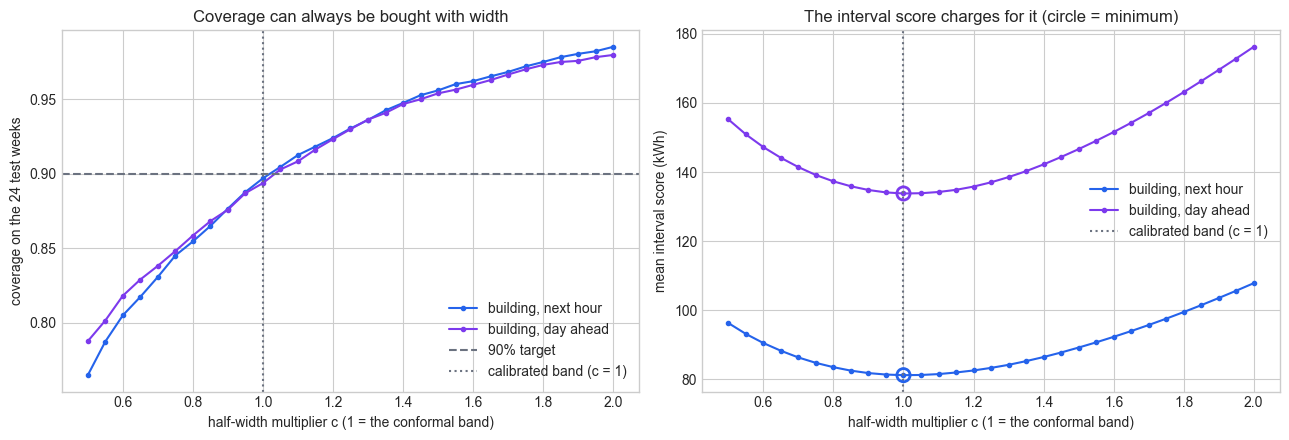

building h=1   c=0.5: cov 0.765, IS   96.3 | c=1: cov 0.897, IS   81.2 | c=2: cov 0.985, IS  107.8 | minimum at c=1.00, IS   81.2
building h=24  c=0.5: cov 0.788, IS  155.2 | c=1: cov 0.894, IS  133.8 | c=2: cov 0.980, IS  176.3 | minimum at c=1.00, IS  133.8
      vm h=1   c=0.5: cov 0.588, IS   25.9 | c=1: cov 0.899, IS   19.8 | c=2: cov 0.984, IS   25.5 | minimum at c=1.00, IS   19.8
      vm h=12  c=0.5: cov 0.774, IS   60.0 | c=1: cov 0.900, IS   56.3 | c=2: cov 0.954, IS   67.3 | minimum at c=0.90, IS   56.1
      vm h=48  c=0.5: cov 0.786, IS   60.2 | c=1: cov 0.914, IS   56.5 | c=2: cov 0.957, IS   68.4 | minimum at c=0.85, IS   56.2


In [12]:
# The hand-worked example above, checked against the function.
for reading, by_hand in ((405.0, 50.0), (433.0, 110.0), (470.0, 850.0)):
    assert math.isclose(interval_score([reading], [380.0], [430.0], ALPHA), by_hand), reading

# Buy coverage with width: scale every half-width by c and watch both metrics.
c_grid = np.round(np.arange(0.5, 2.0 + 1e-9, 0.05), 2)
curves = {}
for key, (res, _) in runs.items():
    y_, p_, q_ = res["y"].to_numpy(), res["point"].to_numpy(), res["q_hat"].to_numpy()
    curves[key] = pd.DataFrame(
        {"coverage": [np.mean(np.abs(y_ - p_) <= c * q_) for c in c_grid],
         "interval_score": [interval_score(y_, p_ - c * q_, p_ + c * q_, ALPHA) for c in c_grid]},
        index=c_grid)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for key, color, label in ((("building", 1), BLUE, "building, next hour"),
                          (("building", 24), PURPLE, "building, day ahead")):
    curve = curves[key]
    axes[0].plot(c_grid, curve["coverage"], color=color, marker="o", markersize=3, label=label)
    axes[1].plot(c_grid, curve["interval_score"], color=color, marker="o", markersize=3, label=label)
    best = curve["interval_score"].idxmin()
    axes[1].scatter([best], [curve.loc[best, "interval_score"]], s=90, facecolor="none",
                    edgecolor=color, linewidth=2, zorder=3)
axes[0].axhline(1 - ALPHA, color=GRAY, linestyle="--", label="90% target")
for ax in axes:
    ax.axvline(1.0, color=GRAY, linestyle=":", label="calibrated band (c = 1)")
    ax.set_xlabel("half-width multiplier c (1 = the conformal band)")
    ax.legend(loc="lower right" if ax is axes[0] else "center right")
axes[0].set_title("Coverage can always be bought with width")
axes[0].set_ylabel("coverage on the 24 test weeks")
axes[1].set_title("The interval score charges for it (circle = minimum)")
axes[1].set_ylabel("mean interval score (kWh)")
plt.tight_layout()
plt.show()

for key, curve in curves.items():
    best = curve["interval_score"].idxmin()
    print(f"{key[0]:>8} h={key[1]:<3} c=0.5: cov {curve.loc[0.5, 'coverage']:.3f}, "
          f"IS {curve.loc[0.5, 'interval_score']:6.1f} | c=1: cov {curve.loc[1.0, 'coverage']:.3f}, "
          f"IS {curve.loc[1.0, 'interval_score']:6.1f} | c=2: cov {curve.loc[2.0, 'coverage']:.3f}, "
          f"IS {curve.loc[2.0, 'interval_score']:6.1f} | minimum at c={best:.2f}, IS {curve['interval_score'].min():6.1f}")

The left panel is the trap: coverage climbs steadily with width, from 0.765 at half the
calibrated band to 0.985 at twice it for the next-hour building forecasts, so anybody who
reports coverage alone can dial in any number they like. The right panel is the referee.
The interval score is U-shaped and its minimum sits at c = 1.00, on our 0.05 grid, for both
building horizons (81.2 kWh next hour, 133.8 day ahead): at the next hour, halving the band costs 19%
more (96.3), doubling it 33% more (107.8). The printout repeats the check on the VM:
the minimum is again at c = 1.00 at five minutes, and at c = 0.90 and 0.85 at one and four
hours, where the curve is so flat that the minimum is under 1% below the calibrated band
(56.1 against 56.3, 56.2 against 56.5). Those two minima are section 3's block-to-block
swings showing through: the one-day VM calibration windows handed some blocks bands that
were too wide (one-hour coverage 0.918 and 0.948 in the two blocks with the widest bands),
and a common shrink trims that excess faster than it adds misses elsewhere. They do not
say "narrow the band by 15%", because the c that minimises the score on the test period is
itself a choice made on the test period - lie number three. Report the interval score
next to coverage, and let it decide between methods whose coverage is similar (field
guide §18).

One paragraph of perspective before you compare with the literature. Published
benchmarks on cloud traces usually report sMAPE, and building-energy work reports NRMSE,
often as CV(RMSE), the root-mean-square error divided by the mean load. Both are
point-accuracy metrics: they say nothing about bands, and a model can top a sMAPE
leaderboard with a band that covers 70%. And sMAPE has several incompatible definitions
in print. Above all, numbers from papers with different splits, horizons, test periods and
cleaning rules are not comparable: section 2 just produced two MAEs for one model on one
building, 14.2 and 15.7 kWh, by changing nothing but the split. Quote the protocol with
the number, or the number means nothing.

## 7. Each hour 90%, the whole day much less

The facilities team buys energy for tomorrow in one go, at midnight, for all 24 hours. A
band that covers 90% of hours is not a promise that a whole day will stay inside its
bands; that is a different, much stronger promise. **Joint coverage** is the share of
days whose every hour lands inside its own band. If misses were independent, each hour
covering 90% would give the whole day $0.9^{24} \approx 0.08$: 0.9 multiplied by itself
24 times, one factor per hour, so fewer than one day in twelve would get through
clean. Misses are not independent - notebook 10 showed they travel together - which pushes
joint coverage up, since a good day tends to be good everywhere, but nowhere near 0.90.

We measure it with the cheapest honest forecaster in the project, so that no model fit is
needed: "same hour last week" for every hour of tomorrow, issued at midnight (the 23:00
reading is the last one in), with notebook 02's absolute-residual band calibrated per
horizon. For each horizon we use one score per day, from the previous 8 weeks of
midnight-issued forecasts at that horizon; every one of those targets is observed by the
origin, so no purge is needed beyond the window ending yesterday. (Four weeks would give 28
scores per horizon, where the corrected quantile is the 27th smallest, the second largest; 8
weeks gives 56, where it is the 52nd.)
Test days are the same last 24 weeks of 2017 as the walk-forward test.

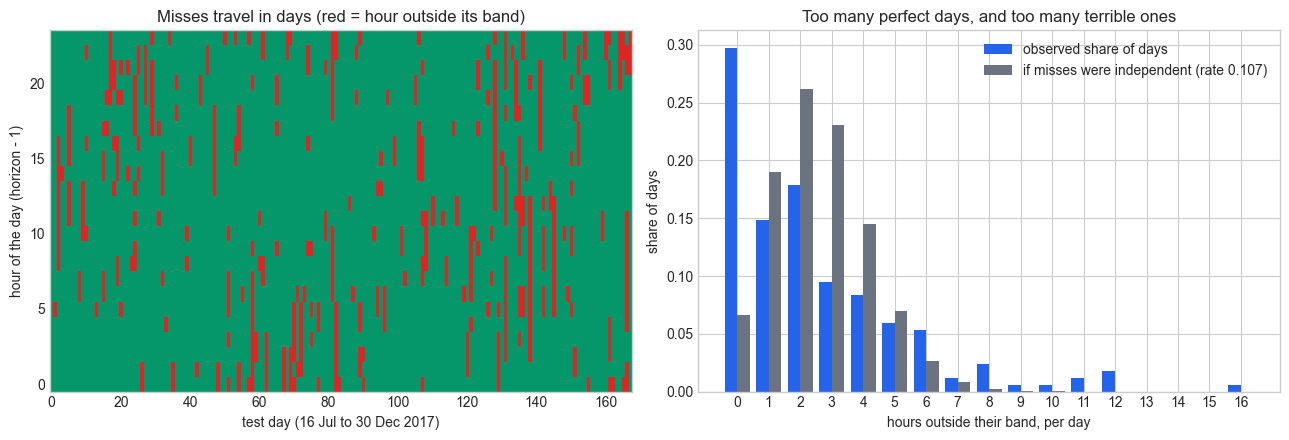

per-hour coverage: 0.863 to 0.923 (mean 0.893; exchangeable days would give 52/57 = 0.912)
joint coverage (all 24 hours inside): 0.298 of 168 days
if misses were independent: 0.9^24 = 0.080; with these per-hour rates 0.065
missed hours per day: mean 2.57, variance 8.58 (independent: 2.30); days with 5 or more: 0.196 (independent: 0.107)
worst day: Fri 2017-11-24, 16 of 24 hours outside


exchangeable days, 1,000 shuffles of whole days: mean coverage 0.913, SD 0.0043, lowest 0.895; shuffles at or below 0.893: 0
Bonferroni, alpha/24 per hour: needs at least 239 calibration days per hour; this window has 56


In [13]:
# Cheap forecasts, no model fits: "same hour last week" for every hour of tomorrow,
# issued at midnight (origin 23:00 -> targets 00:00 ... 23:00 of the next day).
errors = {}
for h in range(1, 25):
    tab = make_direct_table(b["load_kwh"], h, 24)
    issued = tab[tab.index.hour == 23]
    errors[h] = pd.Series(np.abs(issued["target"] - issued["same_time_last_week"]).to_numpy(),
                          index=pd.DatetimeIndex(issued["target_time"]).normalize())
errors = pd.DataFrame(errors)               # one row per target day, one column per horizon
assert errors.notna().all().all()

CAL_DAYS = 8 * 7                           # one score per day per horizon
test_days = errors.index[-24 * 7:]         # the last 24 weeks, as in the walk-forward test
covered = np.zeros((len(test_days), 24), dtype=bool)
for i, day in enumerate(test_days):
    pos = errors.index.get_loc(day)
    past = errors.iloc[pos - CAL_DAYS:pos]   # targets up to yesterday 23:00, all observed
    q_hat = np.array([corrected_quantile(past[h].to_numpy(), ALPHA) for h in errors.columns])
    covered[i] = errors.loc[day].to_numpy() <= q_hat

per_hour = covered.mean(axis=0)
misses = (~covered).sum(axis=1)
p_miss = 1 - per_hour.mean()
binomial = np.array([math.comb(24, k) * p_miss**k * (1 - p_miss) ** (24 - k) for k in range(25)])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].imshow((~covered).T, aspect="auto", interpolation="nearest",
               cmap=ListedColormap([GREEN, RED]), origin="lower")
axes[0].grid(False)
axes[0].set_title("Misses travel in days (red = hour outside its band)")
axes[0].set_xlabel(f"test day ({test_days[0]:%d %b} to {test_days[-1]:%d %b %Y})")
axes[0].set_ylabel("hour of the day (horizon - 1)")
ks = np.arange(misses.max() + 1)
observed = np.bincount(misses, minlength=len(ks)) / len(misses)
axes[1].bar(ks - 0.2, observed, width=0.4, color=BLUE, label="observed share of days")
axes[1].bar(ks + 0.2, binomial[ks], width=0.4, color=GRAY,
            label=f"if misses were independent (rate {p_miss:.3f})")
axes[1].set_xticks(ks)
axes[1].set_title("Too many perfect days, and too many terrible ones")
axes[1].set_xlabel("hours outside their band, per day")
axes[1].set_ylabel("share of days")
axes[1].legend()
plt.tight_layout()
plt.show()

k_day = math.ceil((CAL_DAYS + 1) * (1 - ALPHA))   # the rank corrected_quantile takes at 56 scores
print(f"per-hour coverage: {per_hour.min():.3f} to {per_hour.max():.3f} (mean {per_hour.mean():.3f}; "
      f"exchangeable days would give {k_day}/{CAL_DAYS + 1} = {k_day / (CAL_DAYS + 1):.3f})")
print(f"joint coverage (all 24 hours inside): {covered.all(axis=1).mean():.3f} of {len(test_days)} days")
print(f"if misses were independent: 0.9^24 = {0.9 ** 24:.3f}; with these per-hour rates "
      f"{np.prod(per_hour):.3f}")
print(f"missed hours per day: mean {misses.mean():.2f}, variance {misses.var():.2f} "
      f"(independent: {24 * p_miss * (1 - p_miss):.2f}); days with 5 or more: "
      f"{np.mean(misses >= 5):.3f} (independent: {binomial[5:].sum():.3f})")
worst = int(np.argmax(misses))
print(f"worst day: {test_days[worst]:%a %Y-%m-%d}, {misses[worst]} of 24 hours outside")

# Is the gap to the rank argument's prediction bad luck? Shuffle whole days (each keeps its 24
# errors), rerun the same sliding calibration, and see how low chance alone takes the mean.
def sliding_coverage(day_errors):
    """Mean per-hour coverage of the test days, each calibrated on the CAL_DAYS days before it
    with corrected_quantile's threshold (the k_day-th smallest), vectorised over days and hours."""
    start = len(day_errors) - len(test_days)
    windows = np.lib.stride_tricks.sliding_window_view(day_errors, CAL_DAYS, axis=0)
    windows = windows[start - CAL_DAYS:start - CAL_DAYS + len(test_days)]   # (day, hour, CAL_DAYS)
    q_hats = np.sort(windows, axis=2)[:, :, k_day - 1]
    return float(np.mean(day_errors[start:] <= q_hats))

day_errors = errors.to_numpy()
assert sliding_coverage(day_errors) == covered.mean(), "the vectorised check must match the loop above"
rng = np.random.default_rng(RANDOM_SEED)
shuffled_cov = np.array([sliding_coverage(day_errors[rng.permutation(len(day_errors))])
                         for _ in range(1_000)])
print(f"exchangeable days, 1,000 shuffles of whole days: mean coverage {shuffled_cov.mean():.3f}, "
      f"SD {shuffled_cov.std():.4f}, lowest {shuffled_cov.min():.3f}; "
      f"shuffles at or below {covered.mean():.3f}: {np.sum(shuffled_cov <= covered.mean())}")

# Bonferroni's price: the smallest calibration set for which corrected_quantile at alpha/24
# does not stop at its assertion (a finite band exists at all).
alpha_hour = ALPHA / 24
n_needed = next(n for n in range(1, 10_000) if math.ceil((n + 1) * (1 - alpha_hour)) <= n)
print(f"Bonferroni, alpha/24 per hour: needs at least {n_needed} calibration days per hour; "
      f"this window has {CAL_DAYS}")

Each hour roughly keeps its own promise: per-hour coverage runs from 0.863 to 0.923, mean
0.893, within noise of 90% for 168 days whose misses travel together. The rank argument
promised more. At 56 scores the corrected quantile is the 52nd smallest, so exchangeable days
would be covered 52/57 = 0.912 of the time, and the shuffle check says how far chance alone
moves that: 1,000 shuffles of whole days give a mean of 0.913, a standard deviation of
0.0043 and a lowest value of 0.895, and none reaches 0.893. The shortfall is the days'
memory - weather spells and a turning season make the 8 weeks behind a test day a poor sample
of it - which is exactly the exchangeability the rank argument assumes. The whole day is
another matter: only 0.298 of the 168 test days had all 24 hours inside their
bands. Independence would have predicted far worse: 0.080 with exactly
90% per hour, 0.065 with these per-hour rates. The heatmap shows why reality beats independence: the red cells are
not sprinkled, they come in vertical streaks: whole days where the building runs differently
from the same day last week. In this simulator that is mostly weather - the temperature
anomaly persists for days (the simulator's comment: "a cold week stays cold") and moves the
heating and cooling load of every hour at once; a real building adds holidays, events and
tenants away. The right panel quantifies it. Missed hours per day have mean 2.57 but
variance 8.58, against 2.30 if misses were independent; there are more perfect days than independence allows (50 of 168, against
0.065 x 168, about 11) and more terrible ones - 19.6% of days had 5 or more misses, against
10.7% - and on the worst day, Friday 2017-11-24, 16 of 24 hours were outside their bands.

What this does not mean: the hourly bands are not broken. They promise 90% of hours, and
deliver it, within noise. What they never promised is a whole day, and a purchase decision that needs
the whole day inside needs a band built for that question. That is an open next step in
this project rather than a solved one. The blunt route is Bonferroni: calibrate each hour
at alpha/24, which guarantees joint coverage of at least 90%. The last printout line is
how blunt: the corrected quantile at alpha/24 needs at least 239 calibration days per hour
before a finite band exists, more than four times our 56-day window - here
`corrected_quantile` would simply stop at its assertion - and where it does exist the band
is far wider. The conformal route is to treat each day as one calibration point with a single
day-level score, such as the worst hour's error divided by its typical size, and take the
corrected quantile of those. Either way, say which coverage you are quoting, hourly or
daily, every time (field guide §19).

## 8. The benchmark table template

Everything so far ends in one table, and its layout is the contract for the rest of Part
II: one row per family, horizon and method, four columns - MAE, coverage, width, interval
score - all measured on the same walk-forward test rows. This notebook fills four rows per
family and horizon:

- `best simple rule (point only)`: the rule chosen in advance - the lowest MAE among
  notebook 10's four rules on the pre-test history - frozen for the whole test period, with
  no band yet (notebook 12 wraps it in one);
- `best rule in hindsight (stress test)`: the rule with the lowest MAE on the test rows
  themselves, labelled as what it is;
- `percentile reference band`: the 14-day median as the point, the 5th-95th percentile
  of the same 14 values as the band - the project's reference, fixed by the protocol
  rather than picked by any score;
- `median GBM + absolute-residual band`: this notebook's walk-forward pipeline.

The headline rule is chosen in advance because choosing it on the test period is lie number
three in a new costume: selection flatters whatever is selected, here the competitor. That
cuts both ways. A model that beats even the hindsight pick has won robustly; a model that
loses only to the hindsight pick has lost to a rule the data alone would not have told
you to deploy (field guide §17). The audition is a small function so that it can be reused unchanged: it
scores every rule on the usable rows before the first test row whose targets are already
observed at that row's origin - the same purge as the calibration window - and freezes the
winner.

In [14]:
def audition_simple_rules(tab, first_test_row, h, rules=BASELINES):
    """Choose the simple rule IN ADVANCE, the way a deployment would have to.

    Scores every rule on the pre-test history: the usable rows before `first_test_row`
    whose targets are already observed at that row's origin (rows 0 .. first_test_row - h,
    the same purge as the calibration window). The rule with the lowest MAE there is frozen
    for the whole test period; ties go to the rule listed first in `rules`.
    Returns (chosen rule, {rule: pre-test MAE}).
    """
    history = tab.iloc[:first_test_row - h + 1]
    mae = {rule: float(np.mean(np.abs(history["target"] - history[rule]))) for rule in rules}
    return min(mae, key=mae.get), mae


rows, audition = [], []
for (fam, h), (res, _) in runs.items():
    tab, cfg = tables[(fam, h)], SETTINGS[fam]
    first_test_row = len(tab) - cfg["test_len"]
    test_rows = tab.iloc[first_test_row:]
    assert (test_rows["target_time"].to_numpy() == res["target_time"].to_numpy()).all(), \
        "rules and model must be scored on the same test rows"
    chosen, mae_pre = audition_simple_rules(tab, first_test_row, h)
    mae_test = {rule: float(np.mean(np.abs(test_rows["target"] - test_rows[rule])))
                for rule in BASELINES}
    hindsight = min(mae_test, key=mae_test.get)
    audition += [{"family": fam, "h": h, "period": "pre-test (audition)", **mae_pre, "pick": chosen},
                 {"family": fam, "h": h, "period": "test period", **mae_test, "pick": hindsight}]
    rows += [
        {"family": fam, "h": h, "method": "best simple rule (point only)", "point": chosen,
         "MAE": mae_test[chosen], "coverage": np.nan, "width": np.nan, "interval_score": np.nan},
        {"family": fam, "h": h, "method": "best rule in hindsight (stress test)", "point": hindsight,
         "MAE": mae_test[hindsight], "coverage": np.nan, "width": np.nan, "interval_score": np.nan},
        {"family": fam, "h": h, "method": "percentile reference band", "point": "median_14d_same_time",
         **band_report(test_rows["target"], test_rows["median_14d_same_time"],
                       test_rows["p05_14d_same_time"], test_rows["p95_14d_same_time"], ALPHA)},
        {"family": fam, "h": h, "method": "median GBM + absolute-residual band", "point": "median GBM",
         **band_report(res["y"], res["point"], res["lo"], res["hi"], ALPHA)},
    ]
benchmark = pd.DataFrame(rows).set_index(["family", "h", "method"])

print("MAE of the four rules before the test period (the audition) and during it:")
print(pd.DataFrame(audition).set_index(["family", "h", "period"]).round(2).to_string())
print("\nmedian GBM's MAE relative to each rule (negative = the GBM is more accurate):")
for (fam, h), grp in benchmark.groupby(level=[0, 1]):
    mae = grp.droplevel([0, 1])["MAE"]
    gbm = mae["median GBM + absolute-residual band"]
    print(f"{fam:>8} h={h:<3} vs the rule chosen in advance "
          f"{gbm / mae['best simple rule (point only)'] - 1:+7.1%}   "
          f"vs the best rule in hindsight {gbm / mae['best rule in hindsight (stress test)'] - 1:+7.1%}")

# Why the VM audition could not find the 14-day median: a median of 14 daily values follows
# a level jump only once more than half of its window lies after the jump.
daily_level = v["cpu_pct"].resample("D").median()
jumps = daily_level.diff()[lambda step: step > 5]
vm_tab = tables[("vm", 12)]
history = vm_tab.iloc[:len(vm_tab) - SETTINGS["vm"]["test_len"] - 12 + 1]   # the h = 12 audition rows
daily_error = ((history["target"] - history["median_14d_same_time"]).abs()
               .groupby(history["target_time"].dt.date).mean())
print("\nVM level jumps in the daily median CPU: "
      + ", ".join(f"{day:%d %b} ({step:+.1f})" for day, step in jumps.items()))
print("VM h=12, the 14-day median's MAE per audition day: "
      + ", ".join(f"{day:%d %b} {err:.2f}" for day, err in daily_error.items()))
benchmark.round(3)

MAE of the four rules before the test period (the audition) and during it:
                                 last_value  same_time_yesterday  same_time_last_week  median_14d_same_time                  pick
family   h  period                                                                                                               
building 1  pre-test (audition)       19.82                42.85                21.82                 39.71            last_value
            test period               19.63                43.32                24.12                 40.05            last_value
         24 pre-test (audition)       42.71                42.71                21.84                 39.63   same_time_last_week
            test period               43.32                43.32                24.12                 40.05   same_time_last_week
vm       1  pre-test (audition)        2.70                 7.07                10.84                  7.98            last_value
            tes

point     MAE  coverage    width  interval_score
family   h  method                                                                                               
building 1  best simple rule (point only)                   last_value  19.633       NaN      NaN             NaN
            best rule in hindsight (stress test)            last_value  19.633       NaN      NaN             NaN
            percentile reference band             median_14d_same_time  40.055     0.802  127.481         168.046
            median GBM + absolute-residual band             median GBM   9.851     0.897   51.927          81.192
         24 best simple rule (point only)          same_time_last_week  24.118       NaN      NaN             NaN
            best rule in hindsight (stress test)   same_time_last_week  24.118       NaN      NaN             NaN
            percentile reference band             median_14d_same_time  40.055     0.802  127.481         168.046
            median GBM + absolute-residual band             median GBM  15.777     0.894   84.201         133.798
vm       1  best simple rule (point only)                   last_value   2.849       NaN      NaN             NaN
            best rule in hindsight (stress test)            last_value   2.849       NaN      NaN             NaN
            percentile reference band             median_14d_same_time   5.631     0.829   21.935          53.747
            median GBM + absolute-residual band             median GBM   2.674     0.899    9.372          19.830
         12 best simple rule (point only)                   last_value   8.226       NaN      NaN             NaN
            best rule in hindsight (stress test)  median_14d_same_time   5.631       NaN      NaN             NaN
            percentile reference band             median_14d_same_time   5.631     0.829   21.935          53.747
            median GBM + absolute-residual band             median GBM   5.730     0.900   27.848          56.259
         48 best simple rule (point only)          same_time_yesterday   8.246       NaN      NaN             NaN
            best rule in hindsight (stress test)  median_14d_same_time   5.631       NaN      NaN             NaN
            percentile reference band             median_14d_same_time   5.631     0.829   21.935          53.747
            median GBM + absolute-residual band             median GBM   6.063     0.914   28.959          56.539

Read the audition first: in each pair of rows, the upper one is what a forecaster could see
before the test period and the lower one what the test period revealed. For the building,
foresight and hindsight agree. Persistence (`last_value`) wins the audition an hour ahead
(pre-test MAE 19.82 kWh) and stays best in the test (19.63); same hour last week wins a day
ahead (21.84, then 24.12) - with `last_value` and `same_time_yesterday` tied at h = 24 in
both periods (42.71, then 43.32), not a bug: a day ahead, the latest reading *is* the
reading 24 hours before the target. On the VM, foresight and hindsight part ways at one hour
and at four. The audition, run on the eight days before the test, picks persistence at one
hour (6.65 against 8.00 for the 14-day median) and same time yesterday at four (7.04
against 8.07); in the test period those two picks fall to 8.23 and 8.25 % CPU while the
14-day median improves to 5.63. The last two printout lines show why the audition could not
see it coming. The VM's daily level jumped on 04 Jan (+8.5) and 12 Jan (+9.1), and a median
of 14 daily values follows a jump only once more than half of its window lies after it -
notebook 10's "lags a level change by about a week". During the audition week the 14-day
median was still partly remembering the old level, and its daily error fell from 10.22 on
15 Jan to 3.67 on 22 Jan as the window filled with the new one; by the test period it had
caught up and become the best rule.

Now the table. On the building the GBM beats every rule, in advance or in hindsight (they are
the same rules here): 9.85 against 19.63 kWh an hour ahead, 49.8% lower, and 15.78 against
24.12 a day ahead, 34.6% lower, with coverage 0.897 and 0.894 where the percentile reference
band manages 0.802 at a width of 127.5 kWh and an interval score of 168.0, against 81.2 and
133.8. On the VM the honest comparison, against the rule chosen in advance, is a clear win
at every horizon: 6.1% lower MAE at five minutes (2.67 against 2.85), 30.3% at one hour
(5.73 against 8.23) and 26.5% at four hours (6.06 against 8.25). The stress test is
humbler. The best rule in hindsight, the 14-day median, is more accurate than the GBM by
1.8% at one hour and 7.7% at four (5.63 against 5.73 and 6.06), and the percentile reference
band built on it posts a slightly better interval score (53.7 against 56.3 and 56.5) despite
under-covering (0.829), because it is narrower by more than its misses cost. That reference
row was fixed by the protocol, not picked by a score: a forecaster who had committed to the
14-day median on domain grounds (notebook 10: one burst cannot move a median) would have
matched the model, while one who let the data audition the rules would have deployed
persistence and lost by 30%. On cloud series the right simple rule is strong, and finding it
in advance is itself a forecasting problem. Report it exactly that way: "the model beat every
rule we could have chosen in advance, and did not beat the best rule in hindsight" is a
valid, publishable result (field guide §17).

Two reading notes: the percentile rows are identical across horizons within a family,
because the 14 same-time values before a target are known at every origin when h is at most
a day; and none of these rows is final - notebook 12 adds the rule with a conformal band,
CQR on the local GBM, a pre-trained stand-in and an ensemble, in exactly this layout and with
this audition. What the table does not say is which method to deploy: that needs the cost
side - refits, monitoring, audits - which notebook 12 weighs.

## 9. Common mistakes to avoid

1. **Shuffling time-ordered rows before splitting.** `train_test_split(shuffle=True)` or
   `KFold(shuffle=True)` on hourly rows lets every test hour's neighbours into training. Our
   VM backtest claimed MAE 4.62 and coverage 0.902 that way; walking forward in time gave
   6.88 and 0.833 (field guide §15).
2. **Leaving a library's random holdout inside `fit`.** `early_stopping="auto"` switches on
   above 10,000 rows and stops on a random 10% of them - a random split nobody sees. Fix
   the number of trees, or validate on a purged block at the end of the training window.
3. **Trusting coverage to catch leakage.** The centred 3-hour mean cut day-ahead MAE from
   15.8 to 5.3 kWh and the band still covered about 90%, at a third of the honest width.
   Calibration prices whatever the pipeline does, leaks included; run the shuffle test and
   the future-scramble check on every new feature and pipeline (field guide §16).
4. **Using the wrong constant in the leakage test.** Against the training mean, an honest
   median model on a shuffled series showed 14% "skill" from nothing. Compare like with
   like: the median for absolute error, the mean for squared error.
5. **Calibrating on the test block, or forgetting the purge.** In-block calibration returns
   0.902 in every building block by construction, and calibration origins whose targets arrive after
   the block start are test-period outcomes in disguise. Calibrate on earlier data and purge
   those origins; the `h`-row embargo before calibration is cheap extra insurance (field
   guide §2, §15).
6. **One band for all horizons, or one coverage for all hours.** A shared band covered 0.983
   at five minutes and 0.842 at four hours while averaging 0.895; hourly bands that covered
   0.893 of hours on average kept only 0.298 of days fully inside. Calibrate and report per horizon,
   and say whether a coverage is per hour or per day (field guide §19).
7. **Reporting coverage without the interval score.** Coverage rose from 0.765 to 0.985 as we
   scaled the next-hour band from half to double width; only the interval score showed that
   both ends were worse (field guide §18). And never compare sMAPE or NRMSE across papers
   without comparing their protocols.
8. **Choosing the comparison rule in hindsight.** On the VM the rule our audition could have
   chosen in advance lost to the GBM by 30% at one hour; the rule that was best in hindsight
   beat the GBM. Freeze the rule before the test period, and show the hindsight pick only as
   a labelled stress test (field guide §17).

## 10. What to say in the project report

**Strong version**

> We evaluate every forecaster with a rolling-origin backtest: the last 24 weeks of 2017 in
> six four-week blocks for the building, the last 8 days in four two-day blocks for the VM.
> Before each block the model is refitted, and its band is calibrated on a window (four weeks
> or one day) whose targets were all observed when the block started; an h-step embargo
> separates training from calibration. Day ahead, the median GBM reaches MAE 15.8 kWh
> against 24.1 for the best simple rule chosen in advance (same hour last week), and its
> conformal band covers 89.4% of hours (85.7% to 93.5% across blocks) at a mean width of
> 84.2 kWh and interval score 133.8, against 80.2% and 168.0 for the 14-day percentile
> reference band. On the VM the model beats the rule our audition chose in advance at every
> horizon, by 30% at one hour and 26% at four; a stress test against the best rule in
> hindsight, the 14-day median, puts that rule 2% and 8% ahead of the model at those
> horizons. On cloud series the right simple rule is strong, and finding it in advance is
> itself a forecasting problem. A time-shuffled copy of the series leaves the pipeline with
> -1% skill against the best constant, as an honest pipeline must, and no feature changes
> when the future values are altered. Coverage is per hour: with a seasonal-naive
> forecaster and per-horizon bands, only 30% of test days had all 24 hours inside their
> bands. For comparison, a random 80/20 split of the same table would have reported MAE
> 14.2 kWh and 89.9% coverage.

**Weak version**

> Our model achieves 90% coverage and an MAE of 14.2 kWh on a held-out 20% test set, a large
> improvement over the 14-day percentile band.

The weak version quotes the shuffled split's numbers as if they described deployment,
reports one test set with no spread across blocks, hides the horizon, says nothing about
leakage, says "90% coverage" without saying 90% of what (hours, not days), compares against
the weakest reference instead of the best simple rule chosen in advance, and never mentions
the VM horizons where a simple rule picked in hindsight matched the model. Every sentence is
true about the backtest it ran; none of it is true about production.

### The one-line summary

The numbers a backtest produces are only as honest as the information it withholds. Walk
forward in time, refit and recalibrate before each block, purge `h` rows so that nothing the
model or the calibrator sees lies after the origin, shuffle the series to prove that skill
comes from the past rather than from the answer, give every horizon its own band, and report
the interval score next to coverage so that width cannot buy the result. Do all that and the
backtest's 15.8 kWh is a number production can be expected to reproduce; skip it and you are writing next
year's vendor deck.

A backtest is a rehearsal of deployment: rehearse with anything the future would not give you, and the premiere will embarrass you.